# Aggregating categorical ensembles

A categorical ensemble gives every location one category per partition. Turning those members into one
category is the aggregation, and Spatialize offers several. The majority vote takes the category most
partitions name. Its weighted form lets some partitions count more. The ordinal vote takes the median
along an order. Dawid–Skene learns how reliable each partition is and weighs it accordingly, and its
spatial variant also keeps apart categories that may not touch. Here we see when each of them changes
the answer, with every classifier, on a real geological map whose whole extent we know.

## Learning goals

- How the majority vote, the weighted vote, the ordinal vote and Dawid–Skene turn members into a category.
- When Dawid–Skene beats the vote, and why on real ensembles it often does not.
- Every classifier with every aggregation, against the truth.
- Which probabilities to report, the members' shares or Dawid–Skene's posteriors.
- How the spatial variant uses forbidden contacts, with examples from land cover and geology.

*Which aggregation should turn the members into a map?*

## The idea

Read the partitions as annotators, each labelling every location. The **majority vote** trusts them
equally. The **weighted vote** gives each a weight we choose. The **ordinal vote** takes, for ordered
categories, the median of the members, which never lands outside the range they span.

**Dawid–Skene** estimates, for each partition, a confusion matrix, the probability that it names category
$k$ when the truth is $j$. An EM algorithm alternates two steps, the probability of each category at
each location given the partitions' matrices, then the matrices given those probabilities, until the
likelihood settles. A partition that agrees with the others where they agree among themselves earns
weight. One that keeps naming the same category whatever the others say loses it. The model assumes
the partitions err independently of one another, given the truth.

The **spatial variant** adds a list of pairs of categories that may not be adjacent. At each EM step a
category loses, at each location, a penalty proportional to its neighbours' probability of a category
it may not touch, a mean-field approximation. The penalty factor is ours to set. Zero gives the
non-spatial model.

## Step by step

### Voters of unequal reliability

Before the maps, a case where the aggregations must differ. Four hundred items each have a true
category among three. Ten annotators name it right 90 % of the time. Fifteen others always answer
"0", whatever the item.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import spatialize
from spatialize.data import load_lithology_golden
from spatialize.gs.cat_esi import cat_esi_nongriddata
from spatialize.gs.cat_esi.functionals import (aggregate_with_mv, aggregate_with_weighted_mv,
                                                 aggregate_with_ordinal_mv, aggregate_with_btd)
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)

rng = np.random.default_rng(0)
truth_items = rng.integers(0, 3, 400).astype(str)
votes = np.empty((400, 25), dtype=object)
for j in range(10):
    right = rng.random(400) < 0.9
    votes[:, j] = np.where(right, truth_items, rng.integers(0, 3, 400).astype(str))
votes[:, 10:] = "0"

reliable_weights = np.r_[np.ones(10), np.full(15, 0.1)]
pd.Series({"majority vote": (aggregate_with_mv(votes) == truth_items).mean(),
           "weighted vote, reliable annotators weighted 10 to 1": (aggregate_with_weighted_mv(votes, reliable_weights) == truth_items).mean(),
           "Dawid–Skene": (aggregate_with_btd(votes, categories_list=["0", "1", "2"], seed=0, callback=quiet)[0] == truth_items).mean()},
          name="share right").round(3).to_frame()

,share right
majority vote,0.302
"weighted vote, reliable annotators weighted 10 to 1",1.000
Dawid–Skene,1.000


The vote follows the fifteen annotators that always answer "0", right only on the items whose truth is
"0", about a third. The weighted vote recovers the truth, but only because we told it which annotators to
trust. Dawid–Skene finds that out by itself. The biased annotators name "0" whatever the others say, so
their confusion matrices show them uninformative, so the model follows the reliable ten.

### Every classifier with every aggregation

The Golden map, a real geological map with six lithologies on a 120 × 120 grid, gives the truth. Each classifier runs once on 300 samples, every aggregation reading the same members. The weights of the
weighted vote are each partition's agreement with the majority vote, a cheap estimate of its
reliability. The spatial variant forbids the contacts that never occur on the true map, as someone
who knows the area could list them, with a penalty factor of 2.

forbidden contacts alluvium–basalt, alluvium–granite, basalt–gneiss, basalt–granite, basalt–shale, gneiss–shale, granite–sandstone


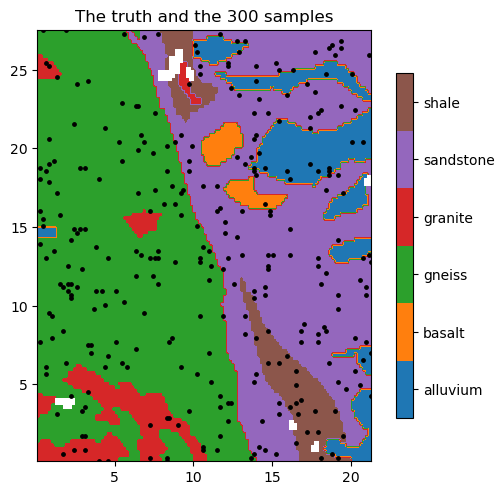

,majority vote,weighted vote,Dawid–Skene,spatial Dawid–Skene,cells the spatial variant changes,partitions' agreement with the vote
knn,0.783,0.783,0.783,0.783,0,0.90 to 1.00
knn_pca,0.816,0.816,0.807,0.807,0,0.86 to 0.95
svm,0.77,0.77,0.784,0.784,0,0.82 to 0.98
rf,0.829,0.828,0.822,0.822,0,0.90 to 0.98
dt,0.797,0.797,0.783,0.783,8,0.86 to 0.96


In [2]:
samples, grid, _ = load_lithology_golden()
points, rocks = samples[["x", "y"]].values, samples["lithology"].values
xi, truth = grid[["x", "y"]].values, grid["lithology"].values
lithologies = sorted(set(truth) - {""})
true_map = truth.reshape(120, 120)                    # the grid runs along x first, so maps are [y, x]

touching = set()
for a, b in ((true_map[:, 1:], true_map[:, :-1]), (true_map[1:, :], true_map[:-1, :])):
    touching |= {tuple(sorted(pair)) for pair in zip(a.ravel(), b.ravel()) if pair[0] != pair[1]}
forbidden = [pair for pair in itertools.combinations(lithologies, 2) if pair not in touching]
print("forbidden contacts", ", ".join(f"{a}–{b}" for a, b in forbidden))

palette = ListedColormap(plt.cm.tab10.colors[:len(lithologies)])

def lithology_codes(labels):
    # NaN for the few cells that belong to no lithology
    return np.array([lithologies.index(c) if c in lithologies else np.nan for c in labels], float).reshape(120, 120)

fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(lithology_codes(truth), origin="lower", cmap=palette, vmin=-0.5, vmax=len(lithologies) - 0.5,
               extent=(grid.x.min(), grid.x.max(), grid.y.min(), grid.y.max()))
ax.scatter(points[:, 0], points[:, 1], s=6, c="black")
cbar = fig.colorbar(im, ax=ax, ticks=range(len(lithologies)), shrink=0.8)
cbar.ax.set_yticklabels(lithologies)
ax.set_title("The truth and the 300 samples")
plt.show()

rows, members = {}, {}
for classifier in ("knn", "knn_pca", "svm", "rf", "dt"):
    m = cat_esi_nongriddata(points, rocks, xi, classifier=classifier, n_partitions=100, alpha=0.7, seed=0).esi_samples(raw=True)
    members[classifier] = m
    vote = aggregate_with_mv(m)
    agreement = np.array([(m[:, j] == vote).mean() for j in range(m.shape[1])])
    ds = aggregate_with_btd(m, categories_list=lithologies, seed=0, callback=quiet)[0]
    spatial = aggregate_with_btd(m, categories_list=lithologies, map_dimensions=(120, 120), spatial_constraints=forbidden,
                                 spatial_penalty_factor=2.0, seed=0, callback=quiet)[0]
    rows[classifier] = {"majority vote": round((vote == truth).mean(), 3),
                        "weighted vote": round((aggregate_with_weighted_mv(m, agreement) == truth).mean(), 3),
                        "Dawid–Skene": round((ds == truth).mean(), 3),
                        "spatial Dawid–Skene": round((spatial == truth).mean(), 3),
                        "cells the spatial variant changes": int((spatial != ds).sum()),
                        "partitions' agreement with the vote": f"{agreement.min():.2f} to {agreement.max():.2f}"}
pd.DataFrame(rows).T

For every classifier the aggregations land within a point and a half of the majority vote. Dawid–Skene
does a point and a half better with the support-vector machine but up to a point and a half worse with
the decision tree. The weighted vote barely moves, since each partition agrees with the vote on 82 % to
100 % of the map, so the weights come out almost equal. The spatial variant changes at most 8 cells of
14 400. On this map the partitions are about equally reliable, so no aggregation has much to correct.

### The probabilities each aggregation gives

Both families give a probability of each category at each location. The vote's are the members' shares
(`class_probabilities()` on a result). Dawid–Skene's are the posterior probabilities of its model. We
compare them where the members disagree.

locations whose members disagree 54%


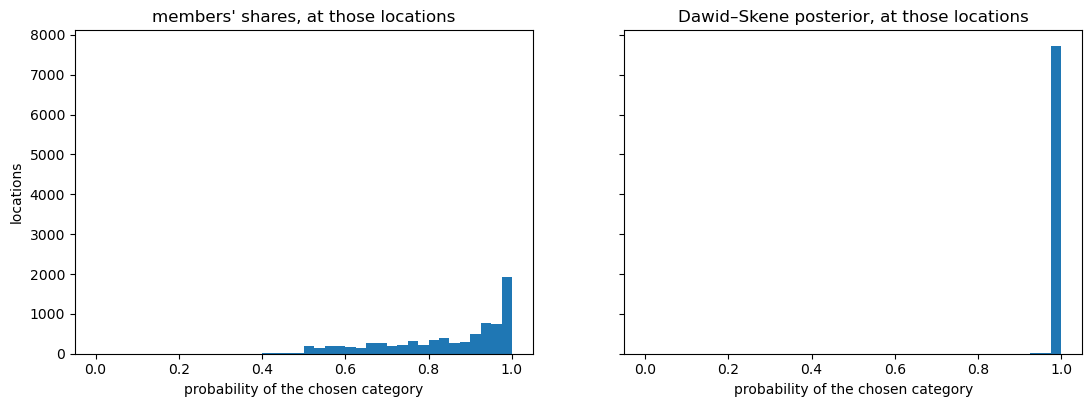

posterior above 0.999 at 98% of them


In [3]:
m = members["knn_pca"]
vote = aggregate_with_mv(m)
shares = np.stack([(m == c).mean(axis=1) for c in lithologies], axis=1)
_, posterior, _ = aggregate_with_btd(m, categories_list=lithologies, seed=0, callback=quiet)
split = shares.max(axis=1) < 1.0
print(f"locations whose members disagree {split.mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (title, p) in zip(axes, [("members' shares", shares), ("Dawid–Skene posterior", posterior)]):
    ax.hist(p[split].max(axis=1), bins=np.linspace(0, 1, 41), color="C0")
    ax.set_title(f"{title}, at those locations")
    ax.set_xlabel("probability of the chosen category")
axes[0].set_ylabel("locations")
plt.show()
print(f"posterior above 0.999 at {np.mean(posterior[split].max(axis=1) > 0.999):.0%} of them")

Where the members disagree, more than half of the map, their shares spread from one half to one. At
98 % of those locations Dawid–Skene's posterior exceeds 0.999. The model treats the partitions as
independent witnesses, yet all of them are trained on the same 300 samples, so it counts the same
evidence many times over. The shares keep the doubt, so they are the probabilities to report.

### Three kinds of variable

A **binary** variable is a nominal one with two categories, here gneiss against the rest, and Dawid–Skene
then learns each partition's sensitivity and specificity. An **ordinal** variable, the geological era,
has the ordinal vote and an ordinal form of Dawid–Skene, which uses the order in its confusion matrices.

In [4]:
binary_rocks = np.where(rocks == "gneiss", "gneiss", "other")
binary_truth = np.where(truth == "gneiss", "gneiss", "other")
mb = cat_esi_nongriddata(points, binary_rocks, xi, classifier="knn_pca", n_partitions=100, alpha=0.7, seed=0).esi_samples(raw=True)

order = {"Cenozoic": 0, "Mesozoic": 1, "Paleozoic": 2, "Proterozoic": 3}
has_era = samples["era"].values != ""
true_era = grid["era"].values
known = true_era != ""
me = cat_esi_nongriddata(points[has_era], samples["era"].values[has_era], xi, classifier="knn_pca",
                         n_partitions=100, alpha=0.7, seed=0).esi_samples(raw=True)

table = {"binary, gneiss or not": {
             "majority vote": (aggregate_with_mv(mb) == binary_truth).mean(),
             "Dawid–Skene": (aggregate_with_btd(mb, category_type="binary", categories_list=["gneiss", "other"],
                                                seed=0, callback=quiet)[0] == binary_truth).mean()},
         "nominal, lithology": {"majority vote": rows["knn_pca"]["majority vote"],
                                "Dawid–Skene": rows["knn_pca"]["Dawid–Skene"]},
         "ordinal, era": {
             "majority vote": (aggregate_with_mv(me)[known] == true_era[known]).mean(),
             "ordinal vote": (aggregate_with_ordinal_mv(me, order)[known] == true_era[known]).mean(),
             "Dawid–Skene": (aggregate_with_btd(me, category_type="ordinal", categories_list=list(order),
                                                ordinal_order_map=order, seed=0, callback=quiet)[0][known] == true_era[known]).mean()}}
pd.DataFrame(table).T.round(3)

,majority vote,Dawid–Skene,ordinal vote
"binary, gneiss or not",0.942,0.943,NaN
"nominal, lithology",0.816,0.807,NaN
"ordinal, era",0.881,0.898,0.882


On the binary variable both give 94 %. On the lithology Dawid–Skene loses a point. On the eras it gains
almost two, 89.8 % against 88.1 % for the vote, while the ordinal vote gains a tenth of a point. Using the
order inside the confusion matrices helps more than taking the median of the members.

### Forbidden contacts

Some categories may not touch. Open water does not border a city directly without a shore between them.
An industrial zone may not adjoin a residential one in a zoning plan. A wetland lies between open water
and dry farmland. In geology, an intrusion meets some units and never others. The spatial variant
takes such pairs and pushes a location away from a category its neighbours rule out.

A strip of twelve locations shows the mechanism. Water may not touch urban land, while wetland may touch
both. Two locations, X1 and X2, are split evenly between water and wetland by their own partitions. X1
lies between two urban locations, X2 between two of wetland.

In [5]:
strip = ["urban", "X1", "urban", "water", "water", "wetland", "X2", "wetland", "urban", "water", "wetland", "urban"]
labels = np.empty((len(strip), 40), dtype=object)
for i, c in enumerate(strip):
    labels[i] = c
    if c.startswith("X"):
        labels[i] = None
        first = 0 if c == "X1" else 20
        labels[i, first:first + 10], labels[i, first + 10:first + 20] = "water", "wetland"

rows_strip = {}
for factor in (0.0, 1.0, 5.0):
    _, p, _ = aggregate_with_btd(labels, categories_list=["urban", "water", "wetland"], map_dimensions=(1, len(strip)),
                                 spatial_constraints=[("water", "urban")], spatial_penalty_factor=factor, seed=0,
                                 callback=quiet)
    rows_strip[f"factor {factor:g}"] = {"P(water) at X1, between urban": p[1, 1], "P(water) at X2, between wetland": p[6, 1]}
pd.DataFrame(rows_strip).T.round(3)

,"P(water) at X1, between urban","P(water) at X2, between wetland"
factor 0,1.0,1.0
factor 1,0.0,1.0
factor 5,0.0,1.0


Without a penalty both X1 and X2 take water, the tie broken the same way at both. From a factor of 1,
X1, between two urban locations, gives up water for wetland, while X2, between two wetland locations,
keeps water. The penalty acts only where a neighbour rules a category out.

On the Golden map with 100 partitions the spatial variant changed only a handful of cells, since the
members agree on nearly every contact. It acts where the members split. With 10 partitions of a coarser
granularity, many locations along the contacts are split, which gives the penalty room to move them.

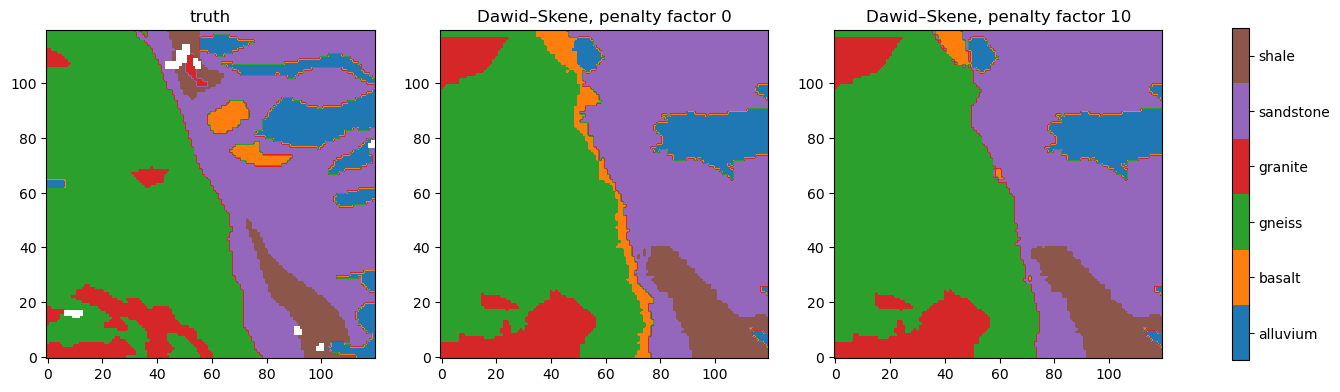

,cells changed,forbidden contacts,share right
factor 0,0.0,208.0,0.774
factor 2,35.0,189.0,0.774
factor 10,399.0,10.0,0.789


In [6]:
few = cat_esi_nongriddata(points, rocks, xi, classifier="knn_pca", n_partitions=10, alpha=0.5, seed=0).esi_samples(raw=True)
banned = set(forbidden)

def forbidden_contacts(labels):
    e = labels.reshape(120, 120)
    return sum(tuple(sorted(pair)) in banned for a, b in ((e[:, 1:], e[:, :-1]), (e[1:, :], e[:-1, :]))
               for pair in zip(a.ravel(), b.ravel()) if pair[0] != pair[1])

base = aggregate_with_btd(few, categories_list=lithologies, seed=0, callback=quiet)[0]
sweep, maps = {}, {}
for factor in (0.0, 2.0, 10.0):
    est = base if factor == 0 else aggregate_with_btd(few, categories_list=lithologies, map_dimensions=(120, 120),
                                                       spatial_constraints=forbidden, spatial_penalty_factor=factor,
                                                       seed=0, callback=quiet)[0]
    maps[factor] = est
    sweep[f"factor {factor:g}"] = {"cells changed": int((est != base).sum()), "forbidden contacts": forbidden_contacts(est),
                                   "share right": round((est == truth).mean(), 3)}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
for ax, (title, labels) in zip(axes, [("truth", truth), ("Dawid–Skene, penalty factor 0", maps[0.0]),
                                      ("Dawid–Skene, penalty factor 10", maps[10.0])]):
    im = ax.imshow(lithology_codes(labels), origin="lower", cmap=palette, vmin=-0.5, vmax=len(lithologies) - 0.5)
    ax.set_title(title)
cbar = fig.colorbar(im, ax=axes, ticks=range(len(lithologies)), shrink=0.8)
cbar.ax.set_yticklabels(lithologies)
plt.show()
pd.DataFrame(sweep).T

A factor of 2 moves 35 cells and removes a tenth of the forbidden contacts. A factor of 10 moves 399
cells, leaves 10 of the 208 forbidden contacts, and raises the share right from 77.4 % to 78.9 %. Most
of the change is the thin strip of basalt along the edge of the gneiss, the rock of a single sample,
whose contact with gneiss the true map never shows. With the strip gone, gneiss meets sandstone
directly, as it does in the truth.

### `knn_pca` on bands of categories

When categories form bands, the right neighbours of a location lie along the band. `knn_pca` fits, in
each cell, the direction of the bands from the data and stretches the distances across them, so the
nearest neighbours come from along the band. Bands at 30° on the unit square show the effect.

In [7]:
rng = np.random.default_rng(3)
across = np.array([np.cos(np.radians(30)), np.sin(np.radians(30))])

def bands(x):
    return np.array(["A", "B", "C"])[(np.floor((x @ across) * 6) % 3).astype(int)]

band_points = rng.random((300, 2))
square = np.stack(np.meshgrid((np.arange(80) + 0.5) / 80, (np.arange(80) + 0.5) / 80), -1).reshape(-1, 2)
pd.Series({classifier: (cat_esi_nongriddata(band_points, bands(band_points), square, classifier=classifier,
                                            n_partitions=100, alpha=0.7, seed=0).estimation() == bands(square)).mean()
           for classifier in ("knn", "knn_pca")}, name="share right").round(3).to_frame()

,share right
knn,0.878
knn_pca,0.923


`knn_pca` gets 4.5 points more of the square right. Before a correction in version 1.3 it stretched the
distances along the bands instead of across them, so its cross-validation always fell back on the isotropic metric, leaving it to behave as `knn`.

### The same result on any machine

The members depend on the seed of the partitions, and Dawid–Skene on its own seed, which fixes the
initial confusion matrices of EM. Neither depends on the number of threads.

In [8]:
m50 = cat_esi_nongriddata(points, rocks, xi, classifier="knn_pca", n_partitions=50, alpha=0.7, seed=0).esi_samples(raw=True)
ds_all_threads = aggregate_with_btd(m50, categories_list=lithologies, seed=0, callback=quiet)[1]
with spatialize.session.override(num_threads=1):
    m50_one = cat_esi_nongriddata(points, rocks, xi, classifier="knn_pca", n_partitions=50, alpha=0.7, seed=0).esi_samples(raw=True)
    ds_one_thread = aggregate_with_btd(m50, categories_list=lithologies, seed=0, callback=quiet)[1]
print(f"members identical {np.array_equal(m50, m50_one)}, posteriors identical {np.array_equal(ds_all_threads, ds_one_thread)}")

members identical True, posteriors identical True


## Pitfalls

- **Expecting Dawid–Skene to beat the vote everywhere.** Its advantage comes from partitions of unequal
  reliability. The partitions of one ensemble share the data and are about equally reliable, so on maps
  it moves the accuracy by a point or two either way.
- **Reporting Dawid–Skene's posteriors as probabilities.** The partitions share the data, so their errors are not independent. The model still counts the same evidence many times. Report the members'
  shares as probabilities, and use Dawid–Skene, if at all, for the category.
- **A penalty that changes nothing.** Where the members agree along a contact, the spatial variant has
  nothing to move. Check the number of cells it changes before crediting it.
- **Forbidden contacts read from the answer.** Here the list came from the true map, to show the
  mechanism. In practice it must come from knowledge of the area, or the penalty imposes a pattern the
  data do not support.
- **No seed.** Without `seed`, EM starts from random matrices, so two runs may settle on different local maxima.

## Try it yourself

1. Make five of the ten reliable annotators right only 60 % of the time and watch the weighted vote and
   Dawid–Skene.
2. Run the spatial sweep with the decision tree (`classifier="dt"`) and 20 partitions.
3. Give the weighted vote weights from each partition's cross-validated accuracy.
4. Forbid a contact that does occur on the map, such as gneiss–sandstone, and see what the penalty does
   to the contact.

## Next

- *Estimating categories*, for the classifiers, the probabilities and the disagreement.
- *Choosing an ensemble with the Pareto search*, for the granularity.
- The documentation's [Categorical estimation](https://spatialize.readthedocs.io/en/latest/theory/categorical.html)
  (theory) and [categorical ESI reference](https://spatialize.readthedocs.io/en/latest/reference/cat_esi.html).